In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch, butter, sosfiltfilt
from scipy.interpolate import CubicSpline

# ── Configurable Parameters ────────────────────────────────────────────────────
FS          = 1000.0   # sampling rate (Hz)
DURATION    = 100.0    # recording length (s)
NOISE_FREQ  = 60.0     # line-noise frequency (Hz)

# Sliding-window settings
WINDOW_SIZE_SEC = 1.0  # half-width of each estimation window (s)
WINDOW_STEP_SEC = 0.025 # step between window centers (s); controls time resolution

# Interpolation method: 'linear' or 'cubic'
INTERP_METHOD = 'cubic'
# ──────────────────────────────────────────────────────────────────────────────
print(f"fs={FS} Hz | duration={DURATION} s | noise={NOISE_FREQ} Hz")
print(f"Window half-width={WINDOW_SIZE_SEC} s | step={WINDOW_STEP_SEC} s")
print(f"Samples per half-window: {int(WINDOW_SIZE_SEC * FS)}")


fs=1000.0 Hz | duration=100.0 s | noise=60.0 Hz
Window half-width=1.0 s | step=0.025 s
Samples per half-window: 1000


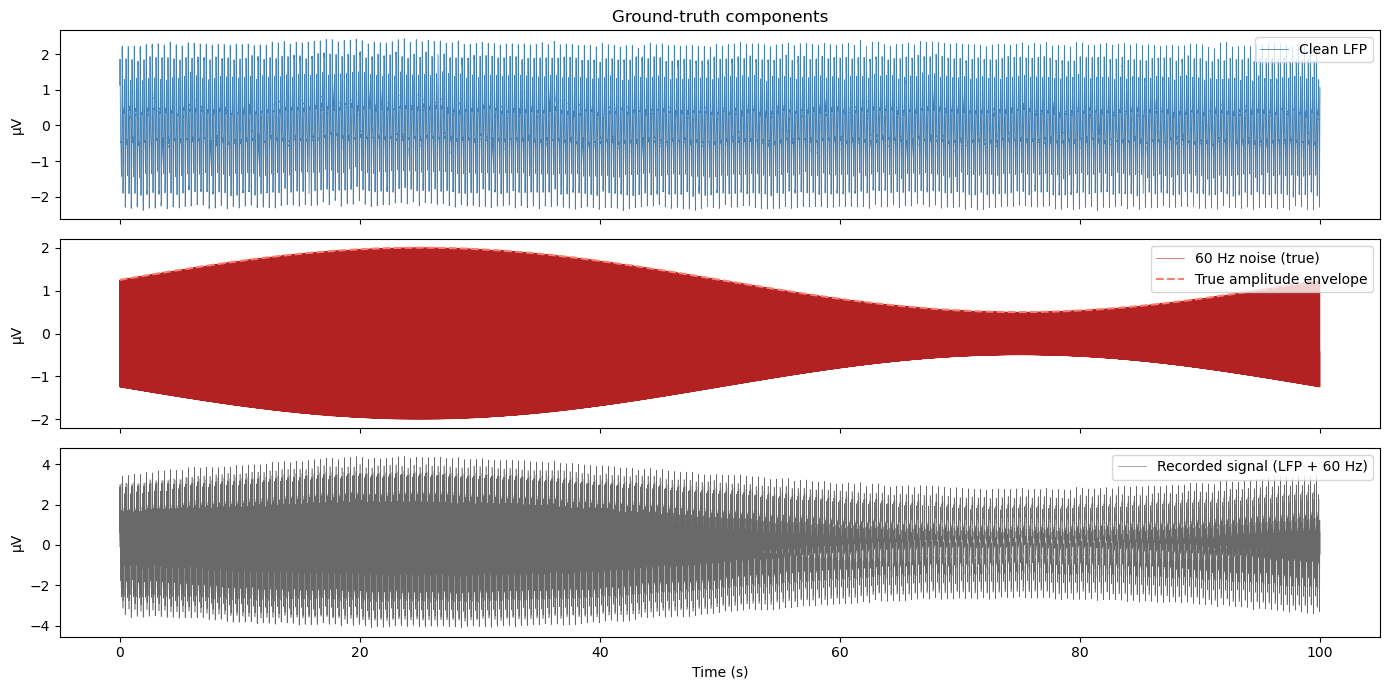

In [12]:
rng = np.random.default_rng(42)

t = np.arange(0, DURATION, 1.0 / FS)  # time vector

# ── Neural LFP components ──────────────────────────────────────────────────────
theta  = 1.5 * np.sin(2 * np.pi * 6  * t + 0.3)   # 6 Hz theta
alpha  = 0.8 * np.sin(2 * np.pi * 10 * t + 1.1)   # 10 Hz alpha

# Pink-ish broadband noise: white noise shaped by 1/sqrt(f) in frequency domain
white  = rng.standard_normal(len(t))
freqs  = np.fft.rfftfreq(len(t), d=1.0 / FS)
freqs[0] = 1.0  # avoid divide-by-zero at DC
spectrum = np.fft.rfft(white) / np.sqrt(freqs)
broadband = np.fft.irfft(spectrum, n=len(t)) * 0.3

lfp_clean = theta + alpha + broadband

# ── Time-varying 60 Hz noise ───────────────────────────────────────────────────
# Amplitude envelope: one full cycle over the entire recording (~0.01 Hz)
true_amp = 1.25 + 0.75 * np.sin(2 * np.pi * 0.01 * t)

# Phase drift: low-pass filtered noise gives a smooth, bounded drift
# 4th-order Butterworth LP at 0.02 Hz → variation on a ~50 s timescale
_sos = butter(4, 0.02, btype='low', fs=FS, output='sos')
phase_drift = sosfiltfilt(_sos, rng.standard_normal(len(t))) * 0.8  # ±0.8 rad peak

true_phase = 2 * np.pi * NOISE_FREQ * t + phase_drift

noise_60hz = true_amp * np.sin(true_phase)

# ── Composite signal ───────────────────────────────────────────────────────────
signal = lfp_clean + noise_60hz

# ── Plot ───────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(14, 7), sharex=True)
axes[0].plot(t, lfp_clean,  lw=0.6, color='steelblue', label='Clean LFP')
axes[0].set_ylabel('µV'); axes[0].legend(loc='upper right'); axes[0].set_title('Ground-truth components')
axes[1].plot(t, noise_60hz, lw=0.4, color='firebrick', label='60 Hz noise (true)')
axes[1].plot(t, true_amp,   lw=1.5, color='salmon', ls='--', label='True amplitude envelope')
axes[1].set_ylabel('µV'); axes[1].legend(loc='upper right')
axes[2].plot(t, signal,     lw=0.4, color='dimgray', label='Recorded signal (LFP + 60 Hz)')
axes[2].set_ylabel('µV'); axes[2].set_xlabel('Time (s)'); axes[2].legend(loc='upper right')
plt.tight_layout()
plt.show()


In [13]:
def estimate_line_noise(signal, t, noise_freq,
                        window_size_sec, window_step_sec,
                        interp_method='cubic'):
    """
    Estimate time-varying amplitude and phase of a single-frequency noise
    component using a sliding least-squares sine fit.

    Within each window the model is:
        y ≈ A·sin(2π·f·t) + B·cos(2π·f·t) + C   (C absorbs local DC)

    A(t) and B(t) are estimated at each window center, then interpolated
    to every sample.  The reconstructed noise is:
        noise_est(t) = A_interp(t)·sin(2π·f·t) + B_interp(t)·cos(2π·f·t)

    Parameters
    ----------
    signal          : 1-D array, the contaminated recording
    t               : 1-D array, time axis (s) – must match signal length
    noise_freq      : float, frequency of noise to remove (Hz)
    window_size_sec : float, half-width of the sliding window (s)
    window_step_sec : float, step between window centers (s)
    interp_method   : 'linear' or 'cubic'

    Returns
    -------
    cleaned   : 1-D array, signal with estimated noise subtracted
    noise_est : 1-D array, estimated noise waveform
    A_interp  : 1-D array, interpolated A coefficient (sin component)
    B_interp  : 1-D array, interpolated B coefficient (cos component)
    t_centers : 1-D array, window-center times
    A_vals    : 1-D array, A estimates at each window center
    B_vals    : 1-D array, B estimates at each window center
    """
    fs = 1.0 / (t[1] - t[0])
    half_win = int(round(window_size_sec * fs))
    step     = max(1, int(round(window_step_sec * fs)))
    N        = len(t)

    t_centers, A_vals, B_vals = [], [], []

    # Walk window centers (skip edges where window would be truncated)
    for center in range(half_win, N - half_win, step):
        sl  = slice(center - half_win, center + half_win)
        tw  = t[sl]
        yw  = signal[sl]

        # Design matrix: [sin, cos, DC]
        X = np.column_stack([
            np.sin(2 * np.pi * noise_freq * tw),
            np.cos(2 * np.pi * noise_freq * tw),
            np.ones(len(tw))
        ])
        coeffs, _, _, _ = np.linalg.lstsq(X, yw, rcond=None)

        t_centers.append(t[center])
        A_vals.append(coeffs[0])
        B_vals.append(coeffs[1])

    t_centers = np.array(t_centers)
    A_vals    = np.array(A_vals)
    B_vals    = np.array(B_vals)

    # Interpolate to the full time axis.
    # CubicSpline extrapolation can diverge outside the range of window centers
    # (i.e. the first/last half-window at each edge), so clamp with fill_value.
    if interp_method == 'cubic' and len(t_centers) >= 4:
        A_interp = CubicSpline(t_centers, A_vals, extrapolate=False)(t)
        B_interp = CubicSpline(t_centers, B_vals, extrapolate=False)(t)
        # Fill edge regions (NaN from extrapolate=False) with boundary values
        A_interp = np.where(np.isnan(A_interp), np.interp(t, t_centers, A_vals), A_interp)
        B_interp = np.where(np.isnan(B_interp), np.interp(t, t_centers, B_vals), B_interp)
    else:
        A_interp = np.interp(t, t_centers, A_vals)
        B_interp = np.interp(t, t_centers, B_vals)

    # Reconstruct and subtract
    noise_est = (A_interp * np.sin(2 * np.pi * noise_freq * t) +
                 B_interp * np.cos(2 * np.pi * noise_freq * t))
    cleaned   = signal - noise_est

    return cleaned, noise_est, A_interp, B_interp, t_centers, A_vals, B_vals


print("estimate_line_noise() defined.")


estimate_line_noise() defined.


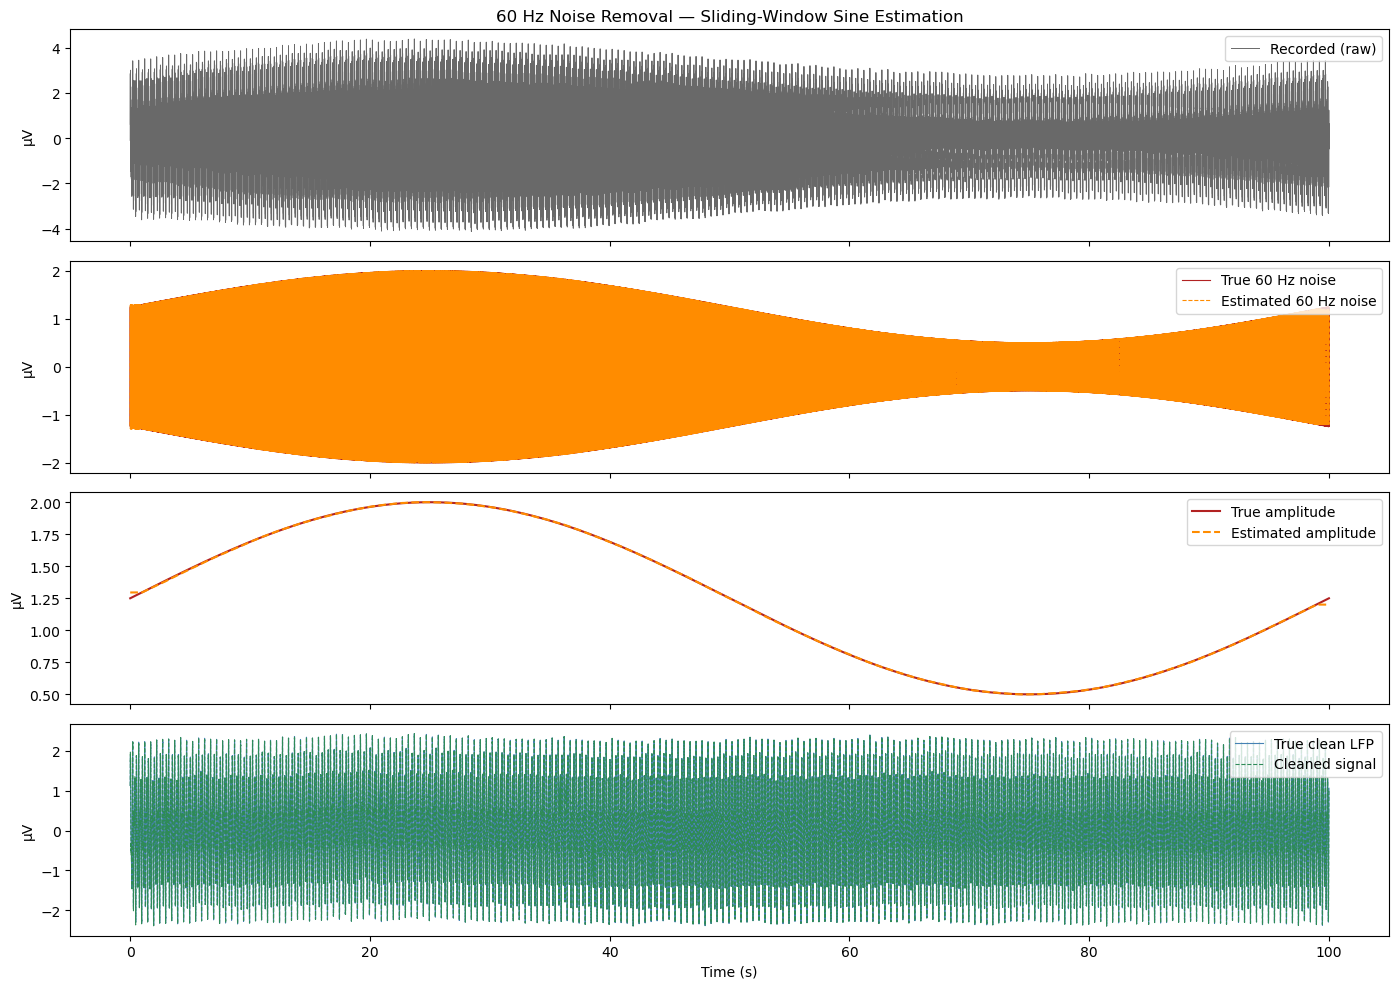

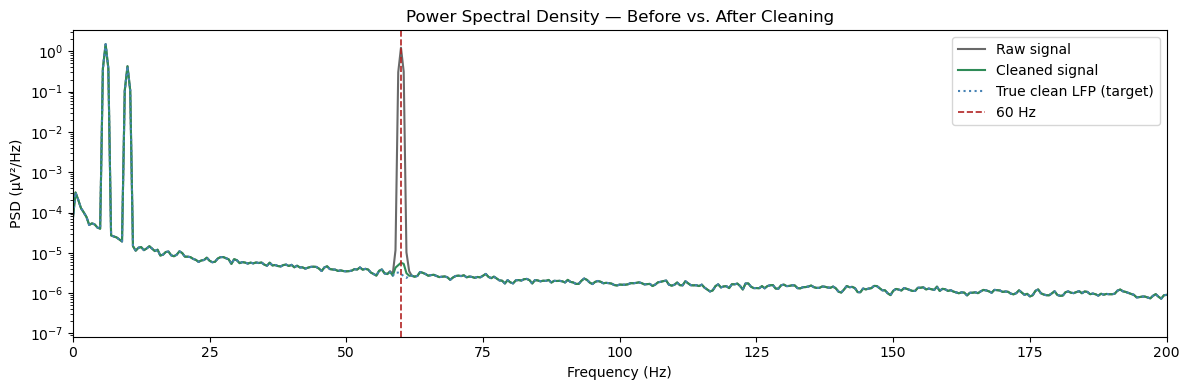

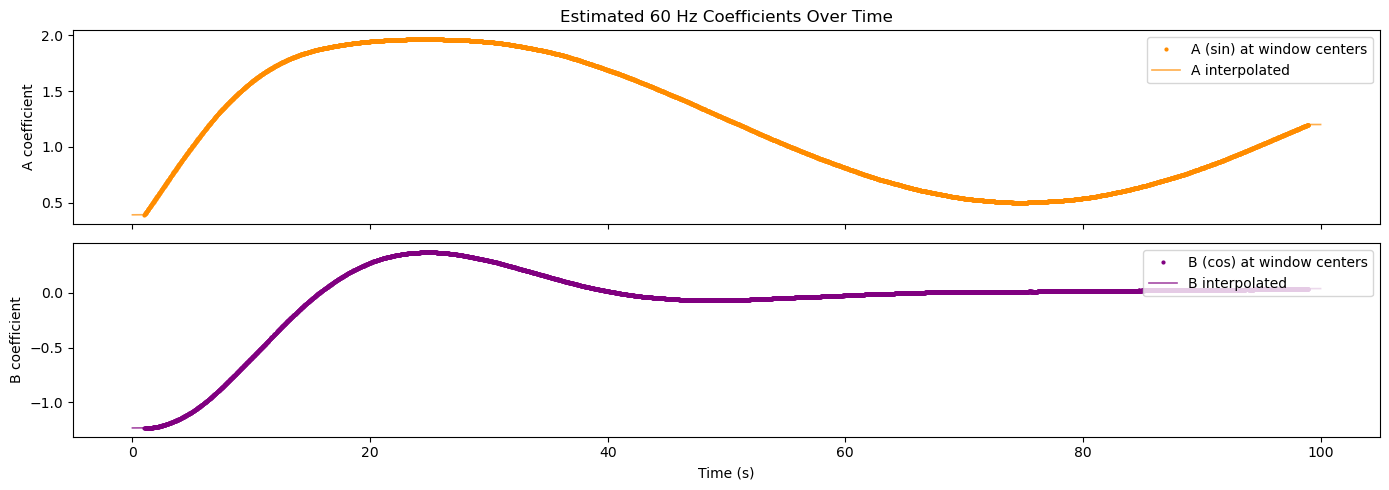

60 Hz suppression: 53.4 dB
Window centers computed: 3920


In [16]:
# ── Run the algorithm ──────────────────────────────────────────────────────────
cleaned, noise_est, A_interp, B_interp, t_centers, A_vals, B_vals = estimate_line_noise(
    signal, t,
    noise_freq      = NOISE_FREQ,
    window_size_sec = WINDOW_SIZE_SEC,
    window_step_sec = WINDOW_STEP_SEC,
    interp_method   = INTERP_METHOD,
)

# ── Derived quantities ─────────────────────────────────────────────────────────
est_amp   = np.sqrt(A_interp**2 + B_interp**2)    # instantaneous amplitude estimate
est_phase = np.arctan2(B_interp, A_interp)          # instantaneous phase estimate

# Residual: how much 60 Hz energy is left in the cleaned signal?
f_psd, psd_raw     = welch(signal,  fs=FS, nperseg=int(FS * 2))
f_psd, psd_cleaned = welch(cleaned, fs=FS, nperseg=int(FS * 2))
f_psd, psd_true    = welch(lfp_clean, fs=FS, nperseg=int(FS * 2))

# ── Figure 1: Time-domain overview ────────────────────────────────────────────
fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)

axes[0].plot(t, signal,    lw=0.7, color='dimgray',   label='Recorded (raw)')
axes[0].set_ylabel('µV'); axes[0].legend(loc='upper right')
axes[0].set_title('60 Hz Noise Removal — Sliding-Window Sine Estimation')

axes[1].plot(t, noise_60hz, lw=0.8, color='firebrick',  label='True 60 Hz noise')
axes[1].plot(t, noise_est,  lw=0.8, color='darkorange', ls='--', label='Estimated 60 Hz noise')
axes[1].set_ylabel('µV'); axes[1].legend(loc='upper right')

axes[2].plot(t, true_amp, lw=1.5, color='firebrick',  label='True amplitude')
axes[2].plot(t, est_amp,  lw=1.5, color='darkorange', ls='--', label='Estimated amplitude')
axes[2].set_ylabel('µV'); axes[2].legend(loc='upper right')

axes[3].plot(t, lfp_clean, lw=0.8, color='steelblue',  label='True clean LFP')
axes[3].plot(t, cleaned,   lw=0.8, color='seagreen',   ls='--', label='Cleaned signal')
axes[3].set_ylabel('µV'); axes[3].set_xlabel('Time (s)'); axes[3].legend(loc='upper right')

plt.tight_layout()
plt.show()

# ── Figure 2: Power spectral density ──────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 4))
ax.semilogy(f_psd, psd_raw,     color='dimgray',   lw=1.5, label='Raw signal')
ax.semilogy(f_psd, psd_cleaned, color='seagreen',  lw=1.5, label='Cleaned signal')
ax.semilogy(f_psd, psd_true,    color='steelblue', lw=1.5, ls=':', label='True clean LFP (target)')
ax.axvline(NOISE_FREQ, color='firebrick', ls='--', lw=1.2, label=f'{NOISE_FREQ:.0f} Hz')
ax.set_xlabel('Frequency (Hz)'); ax.set_ylabel('PSD (µV²/Hz)')
ax.set_title('Power Spectral Density — Before vs. After Cleaning')
ax.legend(); ax.set_xlim(0, 200)
plt.tight_layout()
plt.show()

# ── Figure 3: Coefficient time courses ────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(14, 5), sharex=True)
axes[0].plot(t_centers, A_vals, 'o', ms=2, color='darkorange', label='A (sin) at window centers')
axes[0].plot(t, A_interp,              lw=1.2, color='darkorange', alpha=0.7, label='A interpolated')
axes[0].set_ylabel('A coefficient'); axes[0].legend(loc='upper right')
axes[0].set_title('Estimated 60 Hz Coefficients Over Time')
axes[1].plot(t_centers, B_vals, 'o', ms=2, color='purple', label='B (cos) at window centers')
axes[1].plot(t, B_interp,              lw=1.2, color='purple', alpha=0.7, label='B interpolated')
axes[1].set_ylabel('B coefficient'); axes[1].set_xlabel('Time (s)'); axes[1].legend(loc='upper right')
plt.tight_layout()
plt.show()

# ── Summary metric ─────────────────────────────────────────────────────────────
idx_60 = np.argmin(np.abs(f_psd - NOISE_FREQ))
suppression_dB = 10 * np.log10(psd_raw[idx_60] / psd_cleaned[idx_60])
print(f"60 Hz suppression: {suppression_dB:.1f} dB")
print(f"Window centers computed: {len(t_centers)}")
